In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import requests 
import io
import os
import kagglehub
from kagglehub import KaggleDatasetAdapter

c:\Users\salva\Desktop\Uni\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = pd.read_feather('../data/final_data_ny.feather')
data

,Dayofweek,ret_ny,y_ny,ndx_ret_1d,ndx_ret_5d,ndx_ret_20d,ndx_ret_ny_prev,ndx_vol_20d,vix,vxn,...,ovn_low_dist,ovn_range_pos,prev_ny_high_dist,prev_ny_low_dist,ovn_volume_rel,asia_volume_share,europe_volume_share,last_hour_volume_rel,ovn_vol,ovn_range
,,,,,,,,,,,...,,,,,,,,,,
Date,,,,,,,,,,,,,,,,,,,,,
2023-01-26,3,0.006569,1.0,-0.002701,0.034828,0.072772,0.015239,0.014303,19.080000,24.540001,...,-0.008912,0.910683,-0.006419,-0.027171,1.157739,0.349109,0.650891,1.162806,0.000197,0.009782
2023-01-27,4,0.013770,1.0,0.019844,0.064768,0.107559,0.006569,0.014037,18.730000,25.010000,...,-0.001822,0.426295,0.004650,-0.009468,0.819452,0.301405,0.698595,0.848339,0.000179,0.004268
2023-01-30,0,-0.011250,0.0,0.009507,0.046050,0.130383,0.013770,0.013348,18.510000,24.570000,...,-0.003177,0.219484,0.014998,-0.002989,1.212757,0.371535,0.628465,0.596667,0.000215,0.014392
2023-01-31,1,0.015488,1.0,-0.021115,0.003351,0.084144,-0.011250,0.013947,19.940001,26.250000,...,-0.008927,0.890598,0.009642,-0.002818,1.272247,0.309547,0.690453,1.343076,0.000227,0.010018
2023-02-01,2,0.022510,1.0,0.015786,0.021321,0.100961,0.015488,0.014121,19.400000,25.790001,...,-0.003420,0.601190,0.001402,-0.011304,0.803207,0.317833,0.682167,0.657810,0.000144,0.005683
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-05,4,0.001335,1.0,-0.000971,0.013568,-0.001497,-0.002984,0.012785,15.780000,20.190001,...,-0.001334,0.196023,0.003810,-0.004863,0.569061,0.401577,0.598423,1.182889,0.000120,0.006789
2025-12-08,0,-0.005094,0.0,0.004304,0.010060,0.022118,0.001335,0.011981,15.410000,19.620001,...,-0.004238,0.830508,0.002203,-0.006128,0.511417,0.490834,0.509166,0.632148,0.000113,0.005101


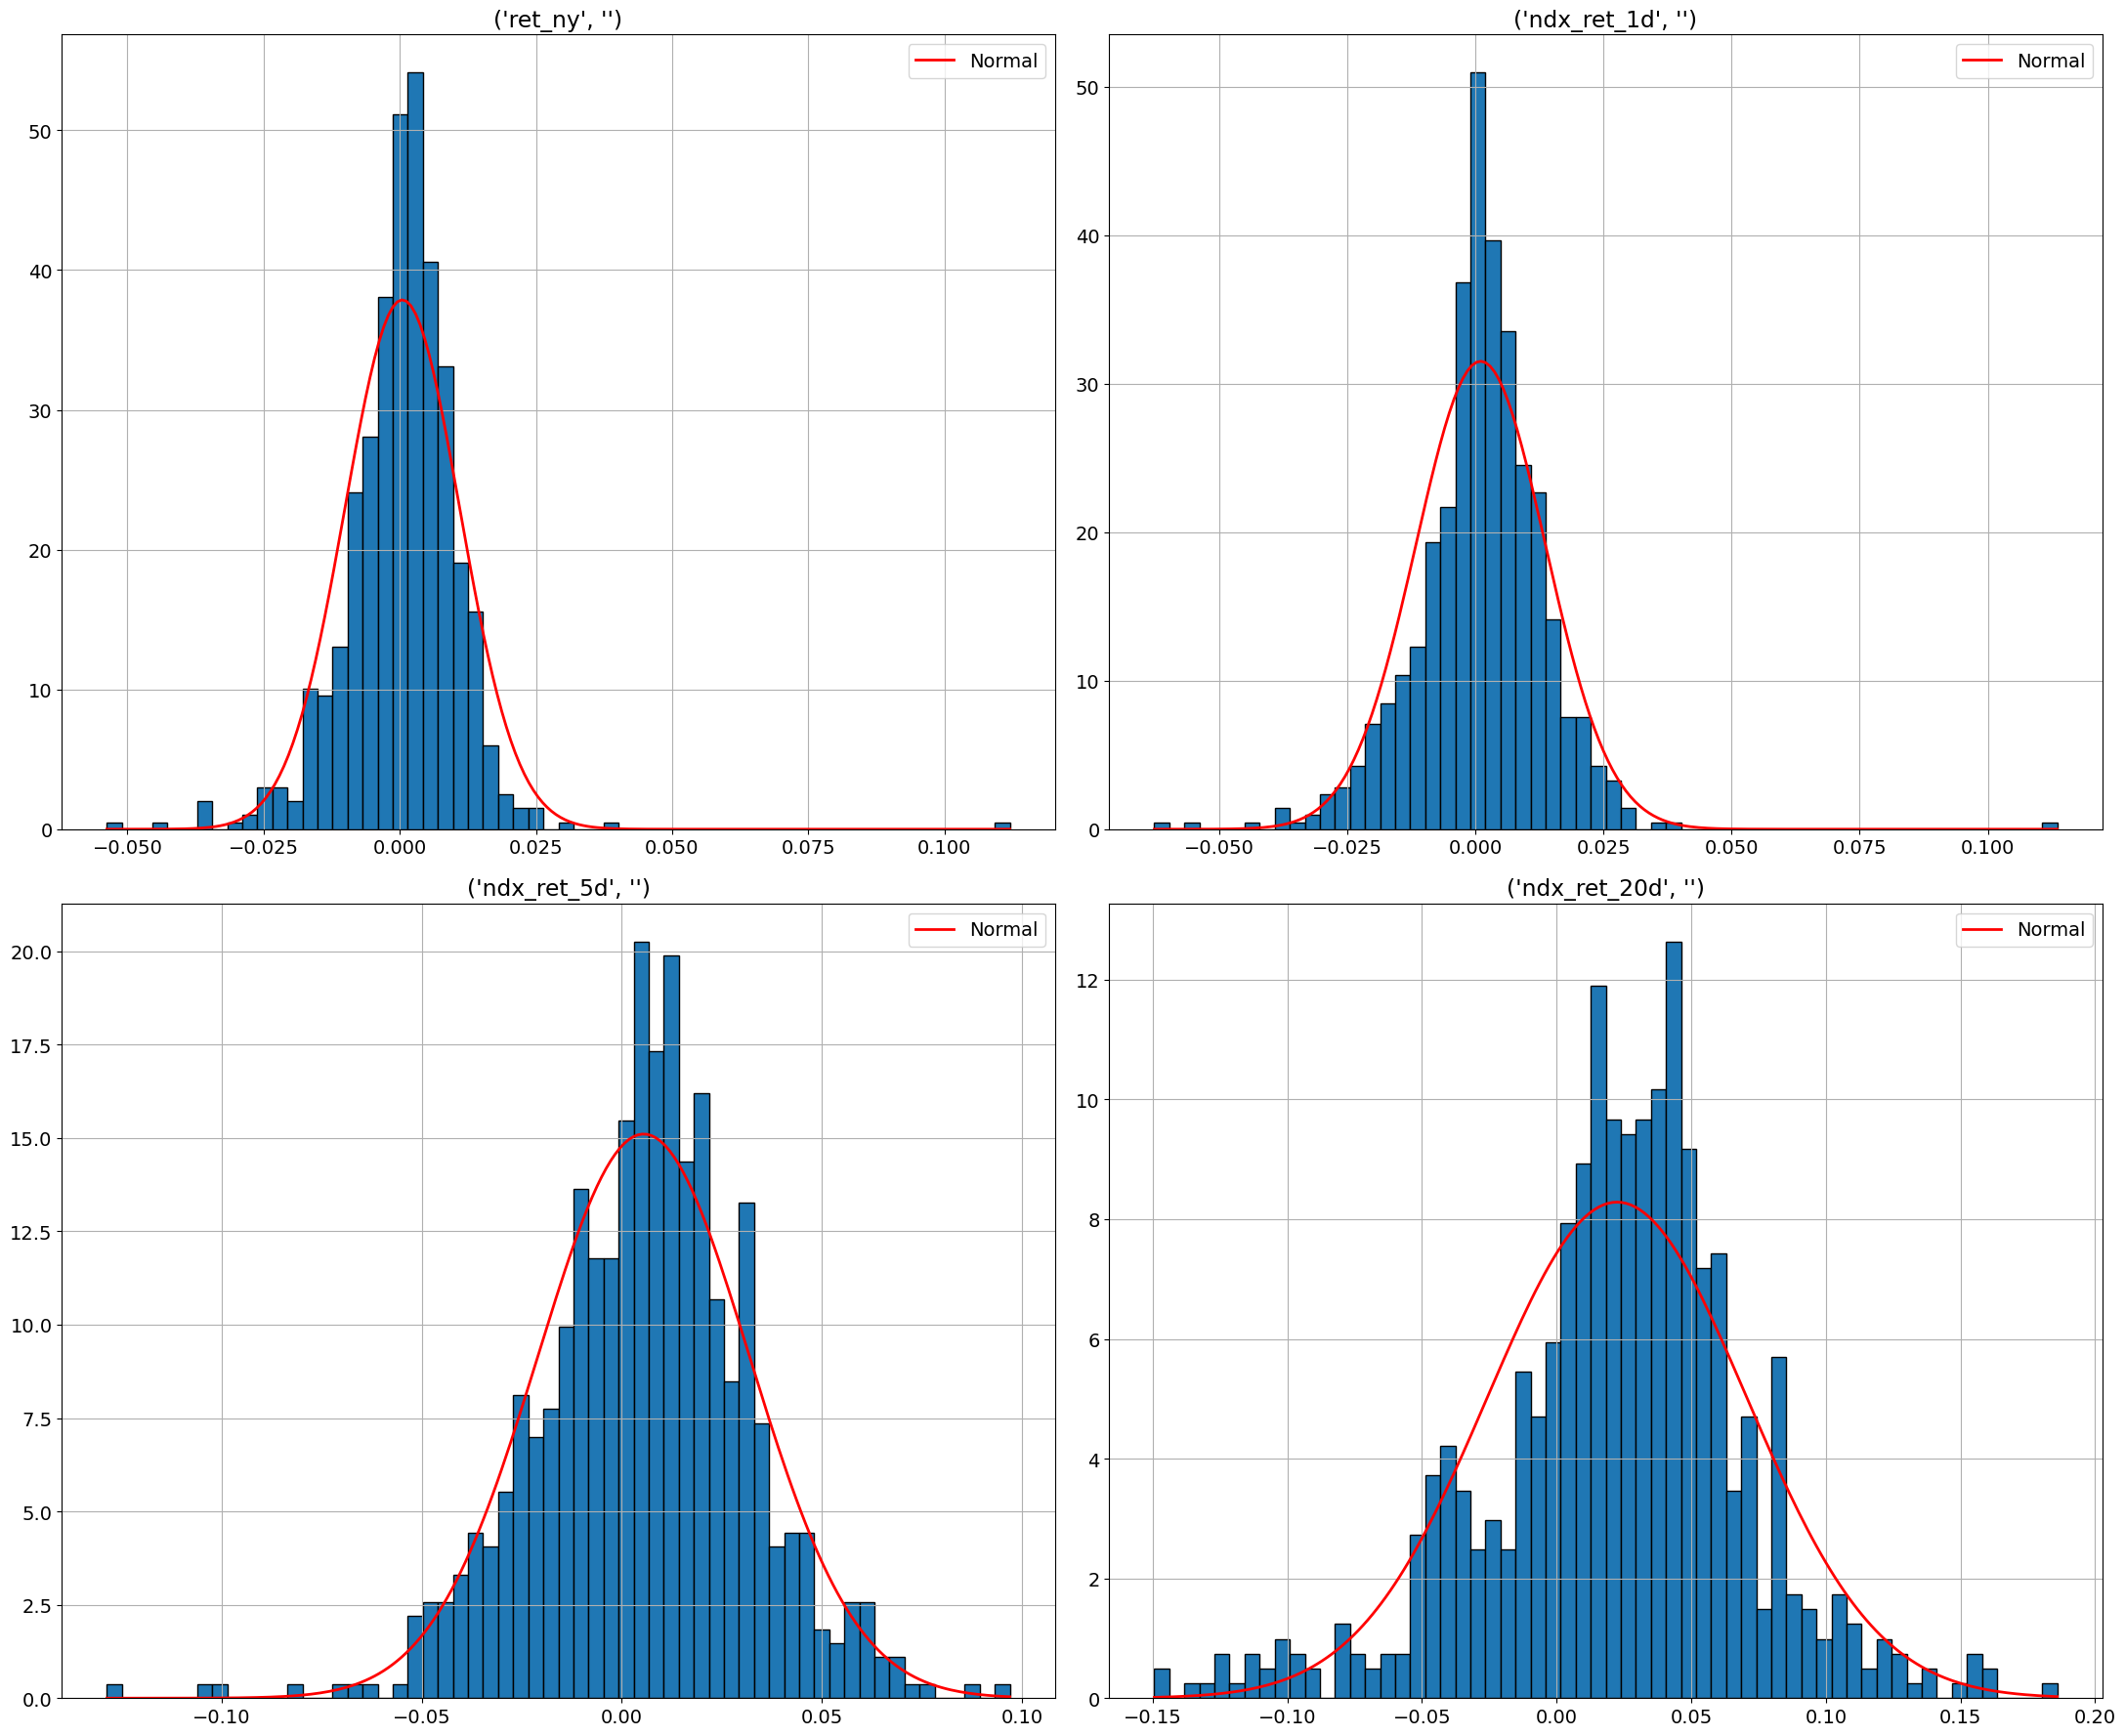

In [3]:
plt.rcParams.update({"font.size": 14})
cols = [('ret_ny',''),('ndx_ret_1d',''),('ndx_ret_5d',''),('ndx_ret_20d','')]
axes = data[cols].hist(bins=60,figsize=(22,18),layout=(2,2),edgecolor='black',density=True)

for ax,col in zip(axes.flatten(),cols):
    x = data[col].dropna()
    mu, sigma = x.mean(), x.std()
    grid = np.linspace(x.min(), x.max(), 200)
    bell = np.exp(-0.5 * ((grid - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
    ax.plot(grid, bell, color="red", linewidth=2, label="Normal")
    ax.legend()

plt.tight_layout()
plt.show()

In [4]:
data[cols].kurtosis()

ret_ny           18.766093
ndx_ret_1d        9.824738
ndx_ret_5d        1.507539
ndx_ret_20d       1.220160
dtype: float64

In [5]:
data[cols].skew()

ret_ny           1.027485
ndx_ret_1d       0.400931
ndx_ret_5d      -0.345787
ndx_ret_20d     -0.410022
dtype: float64

<Axes: xlabel='ovn_ret', ylabel='ret_ny'>

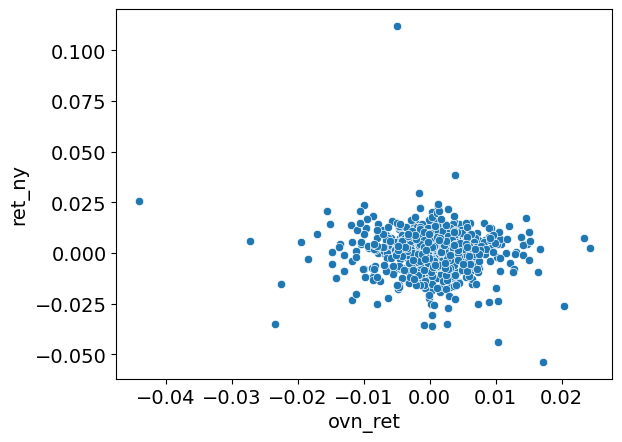

In [6]:
sns.scatterplot(data=data,x=data['ovn_ret'],y=data['ret_ny'])

In [7]:
q = pd.qcut(data[("ovn_ret", "")], 5, labels=["Q1 (most negative)", "Q2", "Q3", "Q4", "Q5 (most positive)"])
print(data.groupby(q)[[("ret_ny", ""), ("y_ny", "")]].mean())

                      ret_ny      y_ny
                                      
(ovn_ret, )                           
Q1 (most negative)  0.001570  0.606897
Q2                  0.000503  0.576389
Q3                  0.000446  0.527778
Q4                  0.000573  0.562500
Q5 (most positive) -0.000767  0.517241


In [9]:
print(data[[("ovn_ret", ""), ("ret_ny", "")]].corr(method="spearman"))

years = data.index.year
print(data.groupby([years, q])[("y_ny", "")].mean().unstack())

           ovn_ret    ret_ny
                            
ovn_ret   1.000000 -0.031294
ret_ny   -0.031294  1.000000


ValueError: Cannot subset columns with a tuple with more than one element. Use a list instead.